## Logistic regression results evaluation
Plots for the logistic regression experiments saved in `../output/logistic_regression/`
(5-fold stratified CV grid search over loss, learning rate, epochs and batch size, then one
hold-out test score per tier with the best combination). The model is the course's
mini-batch gradient-descent logistic regression (`Cross-Fold-Validation-LR.ipynb`).
Churn (`Churn Value = 1`) is the positive class. Same cleaning, seed (2026), 80/20 split
and folds as the k-NN experiment. Plots are also saved to `evaluation/results/logistic_regression/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import precision_recall_curve, roc_curve

OUT = Path("../../output/logistic_regression")
PLOTS = Path("../results/logistic_regression")
PLOTS.mkdir(parents=True, exist_ok=True)

# one colour per tier (fixed order) + a marker per tier so colour is not the only cue
TIERS = ["Tier 1", "Tier 2", "Tier 3"]
COLORS = {"Tier 1": "#2a78d6", "Tier 2": "#eb6834", "Tier 3": "#1baf7a"}
PARAMS = ["loss", "learning_rate", "epochs", "batch_size"]

folds = pd.read_csv(OUT / "fold_results.csv")
grid = pd.read_csv(OUT / "grid_summary.csv")
best = pd.read_csv(OUT / "best_params.csv").set_index("tier")
test = pd.read_csv(OUT / "test_results.csv").set_index("tier")
preds = pd.read_csv(OUT / "test_predictions.csv")
coefs = pd.read_csv(OUT / "coefficients.csv")
sns.set_theme(style="whitegrid")


def save(name):
    plt.savefig(PLOTS / name, dpi=150, bbox_inches="tight")

### Best hyperparameters and test results per tier

In [2]:
display(best.round(3))
display(test[["tp", "fp", "fn", "tn", "precision", "recall", "f_measure", "roc_auc",
              "pr_auc"]].round(3))

,n_features,loss,learning_rate,epochs,batch_size,cv_mean_f_measure,cv_std_f_measure
tier,,,,,,,
Tier 1,4,standard,0.5,200,32,0.546,0.044
Tier 2,6,standard,0.5,200,32,0.585,0.032
Tier 3,19,standard,0.5,200,32,0.634,0.024


,tp,fp,fn,tn,precision,recall,f_measure,roc_auc,pr_auc
tier,,,,,,,,,
Tier 1,155,99,219,936,0.610,0.414,0.494,0.795,0.572
Tier 2,198,128,176,907,0.607,0.529,0.566,0.827,0.640
Tier 3,184,86,190,949,0.681,0.492,0.571,0.851,0.663


### Standard cross-entropy vs Hossein's error function
Best mean CV F-measure each loss reaches over the rest of the grid (the comparison the
course notebook asks for).

loss,hossein,standard
tier,,
Tier 1,0.522,0.546
Tier 2,0.566,0.585
Tier 3,0.592,0.634


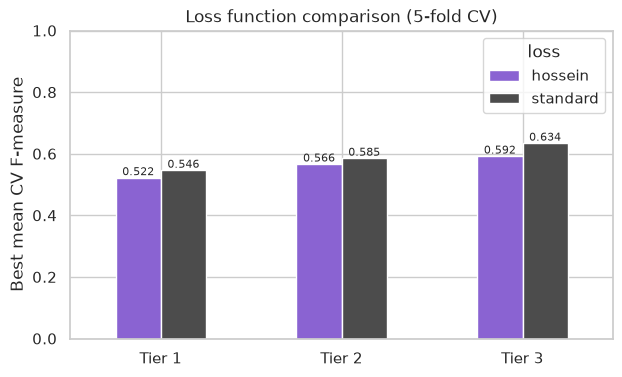

In [3]:
loss_cmp = grid.groupby(["tier", "loss"])["f_measure_mean"].max().unstack()
display(loss_cmp.round(3))
ax = loss_cmp.plot.bar(figsize=(7, 4), rot=0, color=["#8a63d2", "#4c4c4c"])
ax.set(ylabel="Best mean CV F-measure", xlabel="", ylim=(0, 1),
       title="Loss function comparison (5-fold CV)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
save("loss_comparison.png")
plt.show()

### Mean CV F-measure across the grid (standard loss)
Rows: learning rate × epochs; columns: batch size.

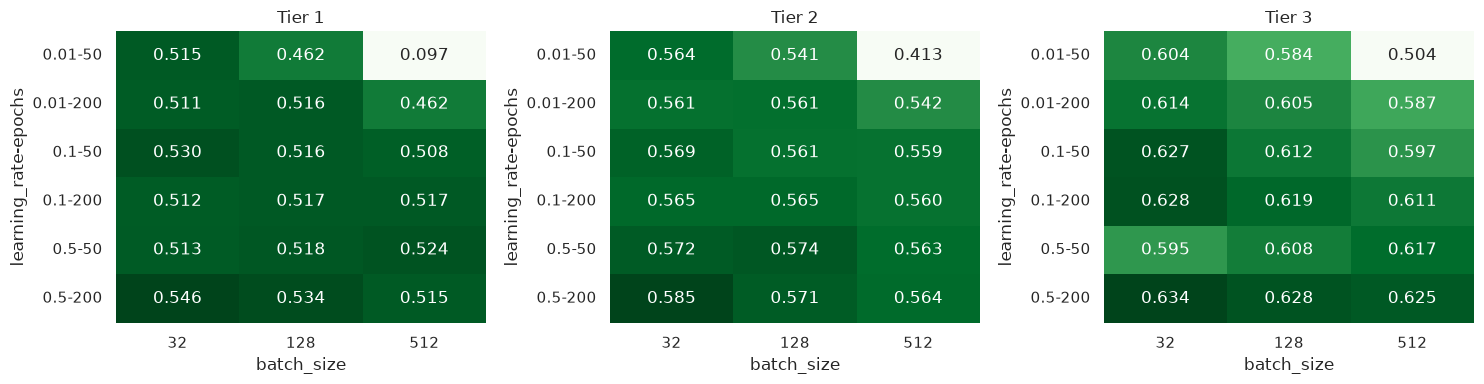

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, tier in zip(axes, TIERS):
    g = grid[(grid["tier"] == tier) & (grid["loss"] == "standard")]
    table = g.pivot_table(index=["learning_rate", "epochs"], columns="batch_size",
                          values="f_measure_mean")
    sns.heatmap(table, annot=True, fmt=".3f", cmap="Greens", cbar=False, ax=ax)
    ax.set_title(tier)
plt.tight_layout()
save("grid_f_measure.png")
plt.show()

### Per-fold results at the best hyperparameters
Each dot is one fold; boxes show the spread across the 5 folds.

/tmp/ipykernel_783/3663558035.py:17: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=long, x="metric", y="value", hue="tier", hue_order=TIERS, dodge=True,


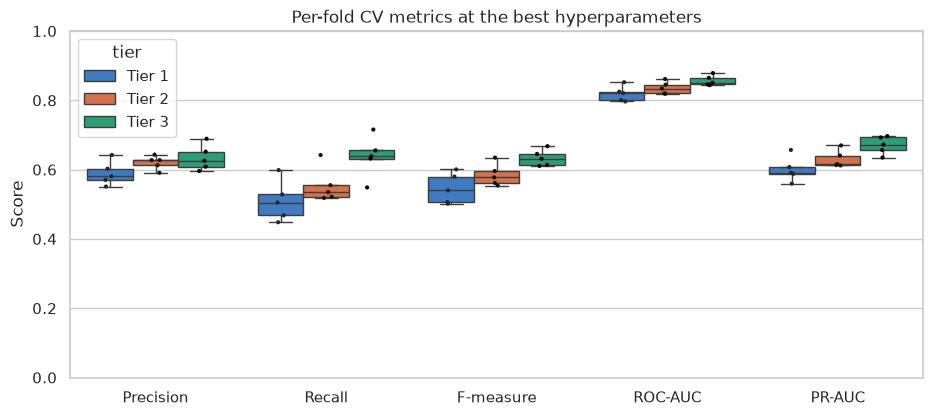

In [5]:
rows = []
for t in TIERS:
    mask = folds["tier"] == t
    for p in PARAMS:
        mask &= folds[p] == best.loc[t, p]
    rows.append(folds[mask])
at_best = pd.concat(rows)
long = at_best.melt(id_vars=["tier", "fold"],
                    value_vars=["precision", "recall", "f_measure", "roc_auc", "pr_auc"],
                    var_name="metric", value_name="value")
long["metric"] = long["metric"].map({"precision": "Precision", "recall": "Recall",
                                     "f_measure": "F-measure", "roc_auc": "ROC-AUC",
                                     "pr_auc": "PR-AUC"})
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=long, x="metric", y="value", hue="tier", hue_order=TIERS, palette=COLORS,
            ax=ax, fliersize=0)
sns.stripplot(data=long, x="metric", y="value", hue="tier", hue_order=TIERS, dodge=True,
              color="black", size=3, ax=ax, legend=False)
ax.set(xlabel="", ylabel="Score", ylim=(0, 1), title="Per-fold CV metrics at the best hyperparameters")
save("per_fold_metrics.png")
plt.show()

### Confusion matrices (hold-out test set)
Layout follows the course `[[TP, FP], [FN, TN]]`: rows are the predicted class, columns
the actual class. Each cell shows the count and its share of all test customers.

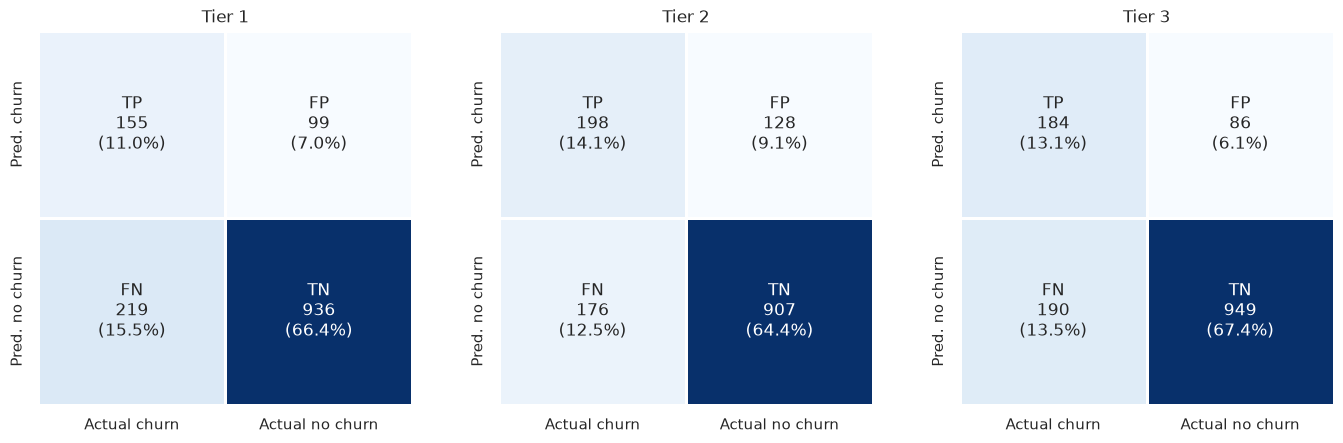

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, tier in zip(axes, TIERS):
    t = test.loc[tier]
    cm = np.array([[t["tp"], t["fp"]], [t["fn"], t["tn"]]]).astype(int)
    names = np.array([["TP", "FP"], ["FN", "TN"]])
    annot = np.array([[f"{names[i, j]}\n{cm[i, j]}\n({cm[i, j] / cm.sum():.1%})"
                       for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, linewidths=2, square=True,
                xticklabels=["Actual churn", "Actual no churn"],
                yticklabels=["Pred. churn", "Pred. no churn"], ax=ax)
    ax.set_title(tier)
plt.tight_layout()
save("confusion_matrices.png")
plt.show()

### ROC and precision-recall curves (hold-out test set)

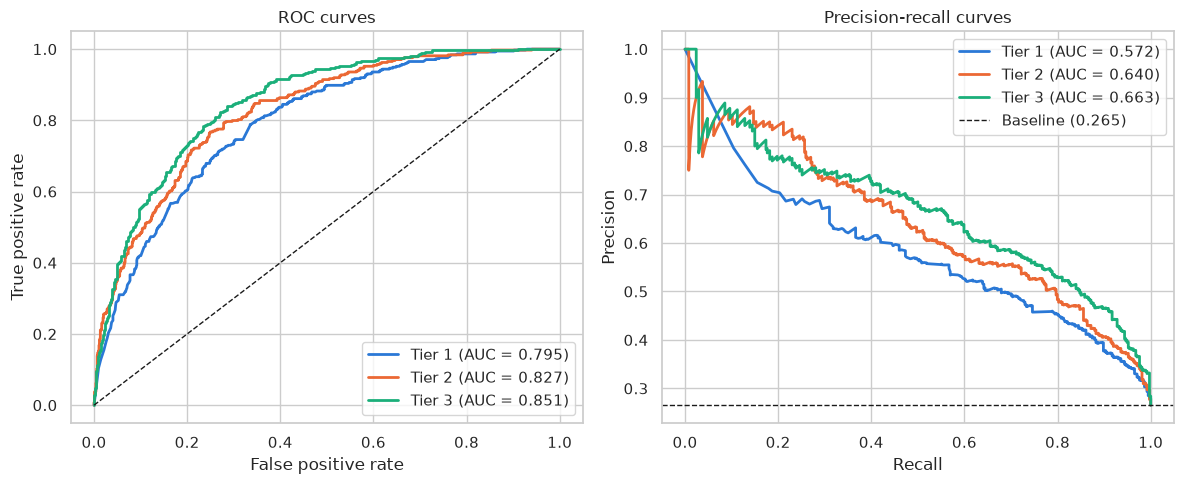

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for tier in TIERS:
    p = preds[preds["tier"] == tier]
    fpr, tpr, _ = roc_curve(p["y_true"], p["y_score"])
    prec, rec, _ = precision_recall_curve(p["y_true"], p["y_score"])
    axes[0].plot(fpr, tpr, color=COLORS[tier], linewidth=2,
                 label=f"{tier} (AUC = {test.loc[tier, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, color=COLORS[tier], linewidth=2,
                 label=f"{tier} (AUC = {test.loc[tier, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
base = preds[preds["tier"] == "Tier 1"]["y_true"].mean()
axes[1].axhline(base, color="k", linestyle="--", linewidth=1, label=f"Baseline ({base:.3f})")
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-recall curves", xlabel="Recall", ylabel="Precision")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
save("roc_pr_curves.png")
plt.show()

### Tier comparison on the test set

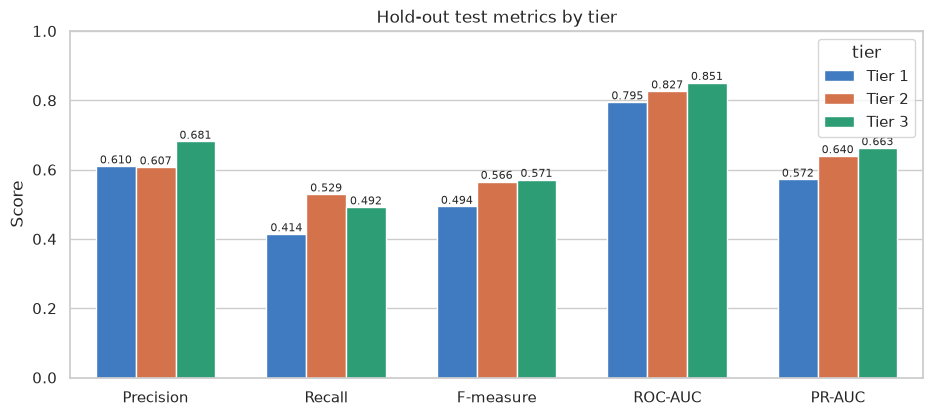

In [8]:
metrics = {"precision": "Precision", "recall": "Recall", "f_measure": "F-measure",
           "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"}
comp = test.reset_index().melt(id_vars="tier", value_vars=list(metrics),
                               var_name="metric", value_name="value")
comp["metric"] = comp["metric"].map(metrics)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=comp, x="metric", y="value", hue="tier", hue_order=TIERS, palette=COLORS,
            width=0.7, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set(xlabel="", ylabel="Score", ylim=(0, 1), title="Hold-out test metrics by tier")
save("tier_comparison.png")
plt.show()

### Largest coefficients (Tier 3)
Inputs are z-scored or one-hot, so magnitudes are comparable. Positive = raises churn odds.

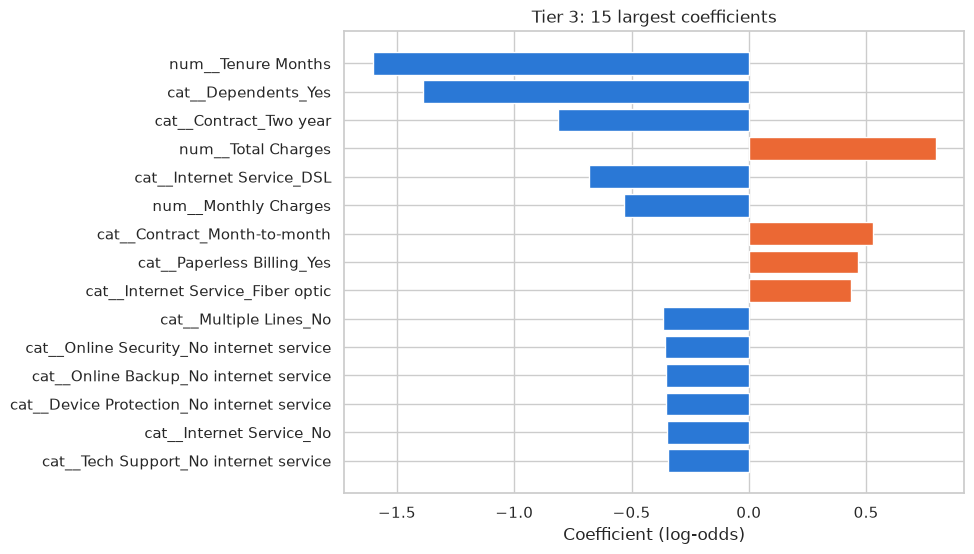

In [9]:
c3 = coefs[(coefs["tier"] == "Tier 3") & (coefs["feature"] != "bias")].copy()
c3 = c3.reindex(c3["coefficient"].abs().sort_values().index).tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(c3["feature"], c3["coefficient"],
        color=np.where(c3["coefficient"] > 0, "#eb6834", "#2a78d6"))
ax.set(xlabel="Coefficient (log-odds)", title="Tier 3: 15 largest coefficients")
save("tier3_coefficients.png")
plt.show()